In [22]:
install.packages(c("tidyverse", "skimr", "ggplot2", "patchwork", "dplyr"))

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



In [28]:
library(tidyverse)
library(skimr)

In [29]:
CA_fire = read_csv("CA_Fire_Data.csv")

Rows: 14988 Columns: 14
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr   (1): SEASON
dbl  (11): PRECIPITATION, MAX_TEMP, MIN_TEMP, AVG_WIND_SPEED, YEAR, TEMP_RAN...
lgl   (1): FIRE_START_DAY
date  (1): DATE

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [30]:
glimpse(CA_fire)

Rows: 14,988
Columns: 14
$ DATE                  <date> 1984-01-01, 1984-01-02, 1984-01-03, 1984-01-04,…
$ PRECIPITATION         <dbl> 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, …
$ MAX_TEMP              <dbl> 79, 71, 70, 76, 74, 65, 59, 59, 61, 70, 68, 69, …
$ MIN_TEMP              <dbl> 51, 46, 47, 45, 49, 49, 54, 55, 54, 47, 46, 47, …
$ AVG_WIND_SPEED        <dbl> 4.70, 5.59, 5.37, 4.70, 5.14, 7.38, 5.82, 3.36, …
$ FIRE_START_DAY        <lgl> FALSE, FALSE, FALSE, FALSE, FALSE, FALSE, FALSE,…
$ YEAR                  <dbl> 1984, 1984, 1984, 1984, 1984, 1984, 1984, 1984, …
$ TEMP_RANGE            <dbl> 28, 25, 23, 31, 25, 16, 5, 4, 7, 23, 22, 22, 14,…
$ WIND_TEMP_RATIO       <dbl> 0.05949367, 0.07873239, 0.07671429, 0.06184211, …
$ MONTH                 <dbl> 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, …
$ SEASON                <chr> "Winter", "Winter", "Winter", "Winter", "Winter"…
$ LAGGED_PRECIPITATION  <dbl> 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, …
$ LAGGED_AVG_WI

In [31]:
CA_fire |>
  select(PRECIPITATION, MAX_TEMP, MIN_TEMP, AVG_WIND_SPEED,
    TEMP_RANGE, WIND_TEMP_RATIO, LAGGED_PRECIPITATION, LAGGED_AVG_WIND_SPEED) |>
  skim()

,skim_type,skim_variable,n_missing,complete_rate,numeric.mean,numeric.sd,numeric.p0,numeric.p25,numeric.p50,numeric.p75,numeric.p100,numeric.hist
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
1,numeric,PRECIPITATION,1,0.9999333,0.03231467,0.17954351,0.00000000,0.0000000,0.0000000,0.0000000,4.5300000,▇▁▁▁▁
2,numeric,MAX_TEMP,1,0.9999333,70.53499700,7.26344731,50.00000000,65.0000000,70.0000000,75.0000000,106.0000000,▂▇▅▁▁
3,numeric,MIN_TEMP,1,0.9999333,56.49409488,6.76768522,33.00000000,51.0000000,57.0000000,62.0000000,77.0000000,▁▃▇▇▁
4,numeric,AVG_WIND_SPEED,12,0.9991994,7.43509816,2.12998454,1.79000000,6.0400000,7.1600000,8.5000000,26.1700000,▅▇▁▁▁
5,numeric,TEMP_RANGE,1,0.9999333,14.04090212,5.99532675,2.00000000,10.0000000,12.0000000,17.0000000,41.0000000,▃▇▂▁▁
6,numeric,WIND_TEMP_RATIO,12,0.9991994,0.10701947,0.03563012,0.02355263,0.0852381,0.1022222,0.1204615,0.4591228,▇▅▁▁▁
7,numeric,LAGGED_PRECIPITATION,0,1.0000000,0.22618762,0.64870473,0.00000000,0.0000000,0.0000000,0.0600000,8.1800000,▇▁▁▁▁
8,numeric,LAGGED_AVG_WIND_SPEED,0,1.0000000,7.43419796,1.38784897,3.22714286,6.5185714,7.4785714,8.2785714,13.9328571,▂▇▇▁▁


In [32]:
CA_fire |>
  select(DATE, PRECIPITATION, MAX_TEMP, MIN_TEMP, AVG_WIND_SPEED, WIND_TEMP_RATIO) |>
  filter(is.na(PRECIPITATION) | is.na(MAX_TEMP) | is.na(MIN_TEMP) | is.na(AVG_WIND_SPEED)) |>
  arrange(DATE) |>
  print(n = 20)

# A tibble: 12 × 6
   DATE       PRECIPITATION MAX_TEMP MIN_TEMP AVG_WIND_SPEED WIND_TEMP_RATIO
   <date>             <dbl>    <dbl>    <dbl>          <dbl>           <dbl>
 1 1997-03-01             0       64       46             NA              NA
 2 1997-03-02             0       60       45             NA              NA
 3 1997-03-03             0       59       47             NA              NA
 4 2024-09-26             0       70       60             NA              NA
 5 2024-12-27             0       61       49             NA              NA
 6 2024-12-28             0       59       53             NA              NA
 7 2024-12-29             0       58       47             NA              NA
 8 2024-12-30             0       62       52             NA              NA
 9 2024-12-31            NA       NA       NA             NA              NA
10 2025-01-01             0       59       47             NA              NA
11 2025-01-11             0       66       46            

Warning message:
“Removed 15 rows containing non-finite outside the scale range (`stat_bin()`).”


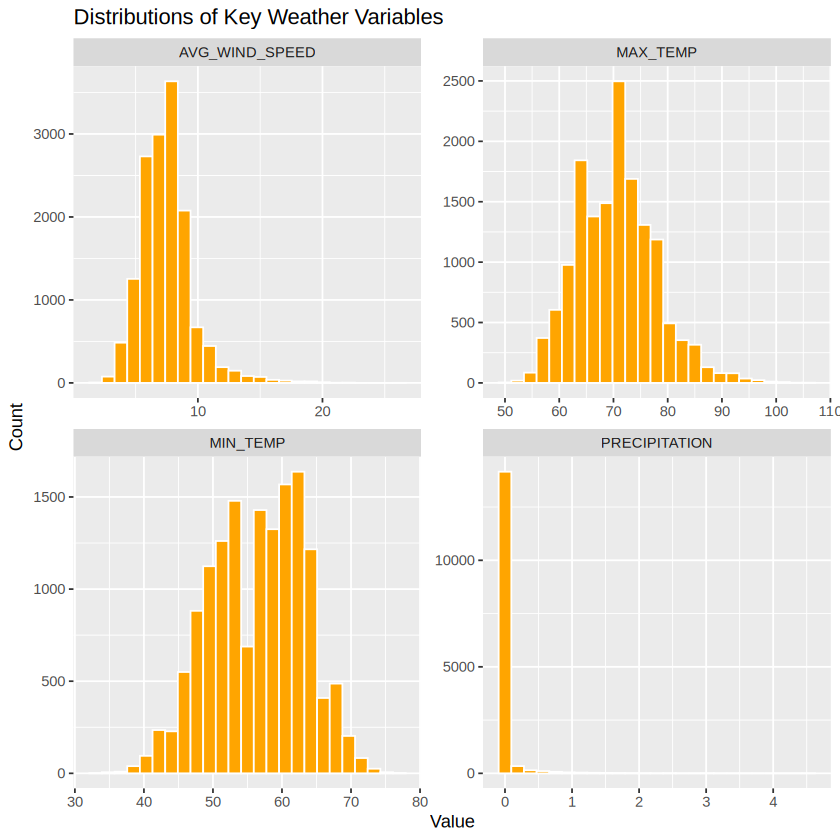

In [33]:
CA_fire |>
  select(MAX_TEMP, MIN_TEMP, AVG_WIND_SPEED, PRECIPITATION) |>
  pivot_longer(cols = everything(), names_to = "variable", values_to = "value") |>
  ggplot(aes(x = value)) +
  geom_histogram(bins = 25, fill = "orange", color = "white") +
  facet_wrap(~variable, scales = "free") +
  labs(title = "Distributions of Key Weather Variables",
       x = "Value",
       y = "Count")

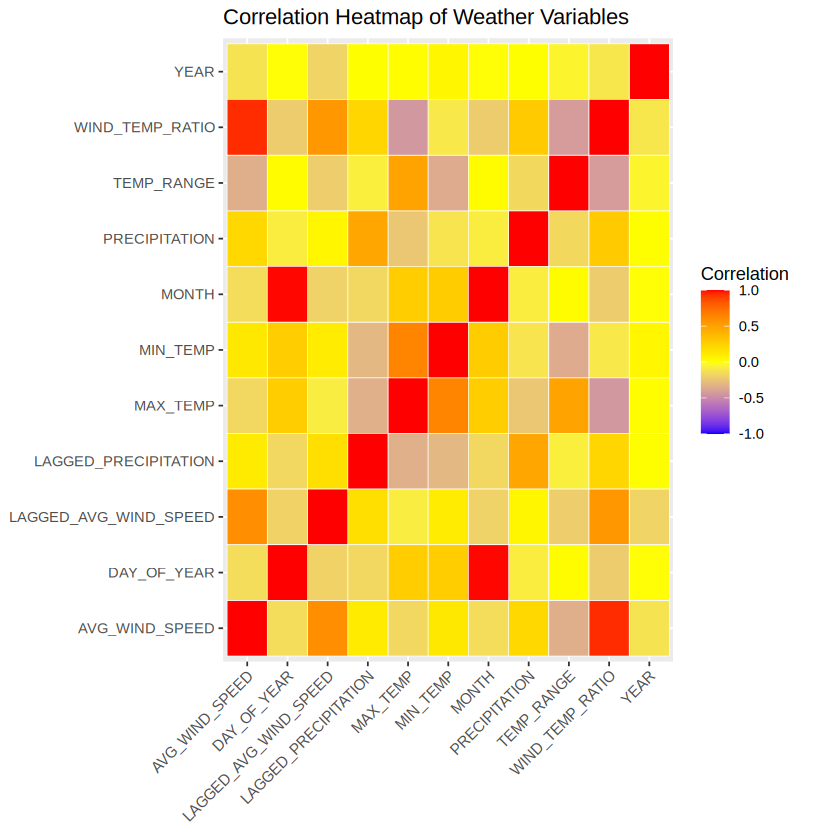

In [34]:
numeric_cols <- CA_fire |>
  select(where(is.numeric)) |>
  drop_na()

cor_matrix <- cor(numeric_cols)

cor_df <- as.data.frame(cor_matrix) |>
  rownames_to_column(var = "Var1") |>
  pivot_longer(-Var1, names_to = "Var2", values_to = "Correlation")

ggplot(cor_df, aes(x = Var1, y = Var2, fill = Correlation)) +
  geom_tile(color = "white") +
  scale_fill_gradient2(low = "blue", mid = "yellow", high = "red",
                       midpoint = 0, limit = c(-1, 1)) +
  theme(axis.text.x = element_text(angle = 45, vjust = 1, hjust = 1)) +
  labs(title = "Correlation Heatmap of Weather Variables", x = "", y = "")

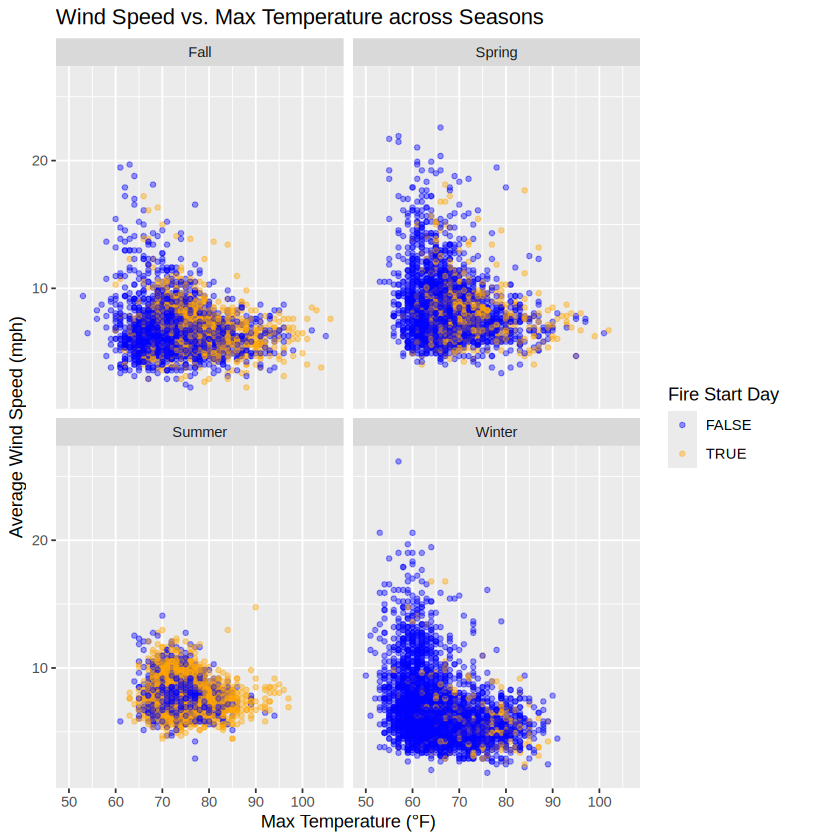

In [35]:
CA_fire |>
  filter(!is.na(MAX_TEMP) & !is.na(AVG_WIND_SPEED)) |>
  ggplot(aes(x = MAX_TEMP, y = AVG_WIND_SPEED, color = FIRE_START_DAY)) +
  geom_point(alpha = 0.4, size = 1.2) +
  facet_wrap(~SEASON) +
  scale_color_manual(values = c("FALSE" = "blue", "TRUE" = "orange")) +
  labs(
    title = "Wind Speed vs. Max Temperature across Seasons",
    x = "Max Temperature (°F)",
    y = "Average Wind Speed (mph)",
    color = "Fire Start Day"
  )

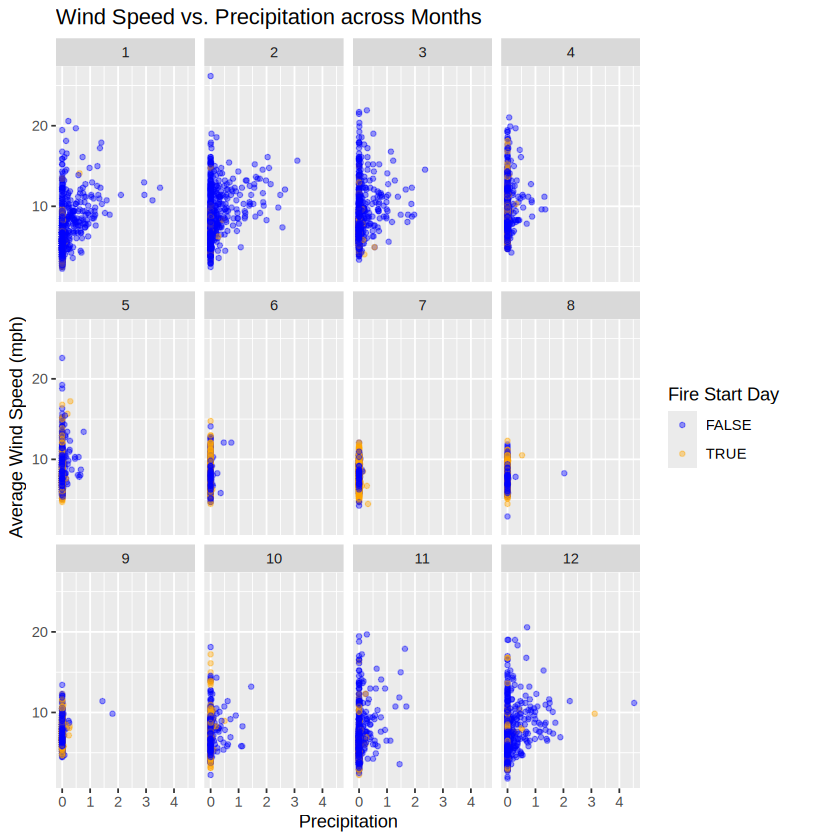

In [36]:
CA_fire |>
  filter(!is.na(PRECIPITATION) & !is.na(AVG_WIND_SPEED)) |>
  ggplot(aes(x = PRECIPITATION, y = AVG_WIND_SPEED, color = FIRE_START_DAY)) +
  geom_point(alpha = 0.4, size = 1.2) +
  facet_wrap(~MONTH) +
  scale_color_manual(values = c("FALSE" = "blue", "TRUE" = "orange")) +
  labs(
    title = "Wind Speed vs. Precipitation across Months",
    x = "Precipitation",
    y = "Average Wind Speed (mph)",
    color = "Fire Start Day"
  )

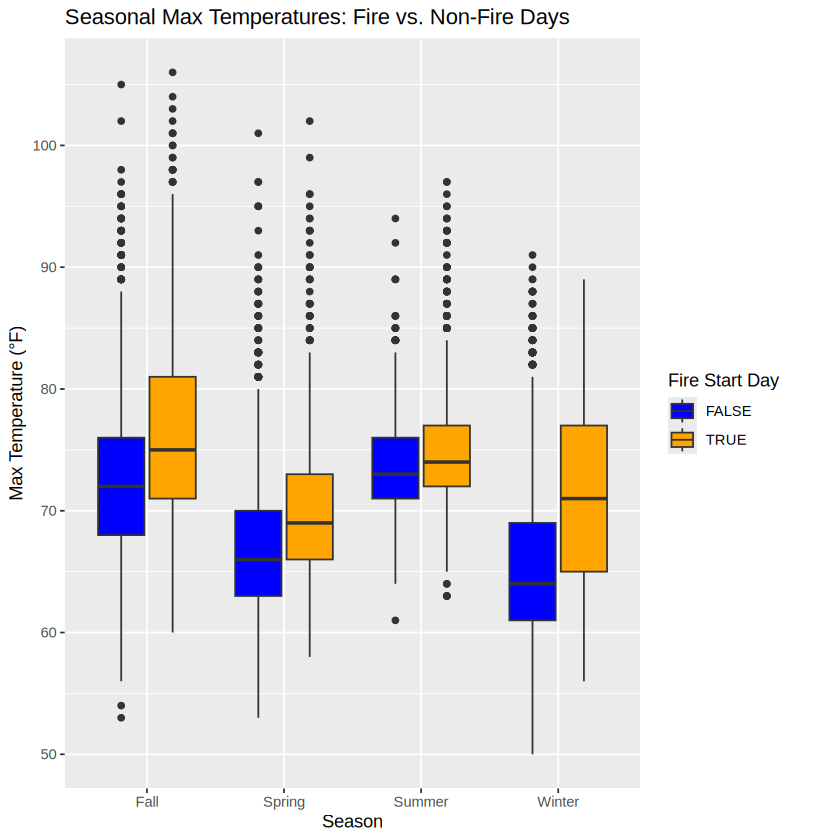

In [37]:
CA_fire |>
  filter(!is.na(MAX_TEMP)) |>
  ggplot(aes(x = SEASON, y = MAX_TEMP, fill = FIRE_START_DAY)) +
  geom_boxplot() +
  scale_fill_manual(values = c("FALSE" = "blue", "TRUE" = "orange")) +
  labs(
    title = "Seasonal Max Temperatures: Fire vs. Non-Fire Days",
    x = "Season",
    y = "Max Temperature (°F)",
    fill = "Fire Start Day"
  )

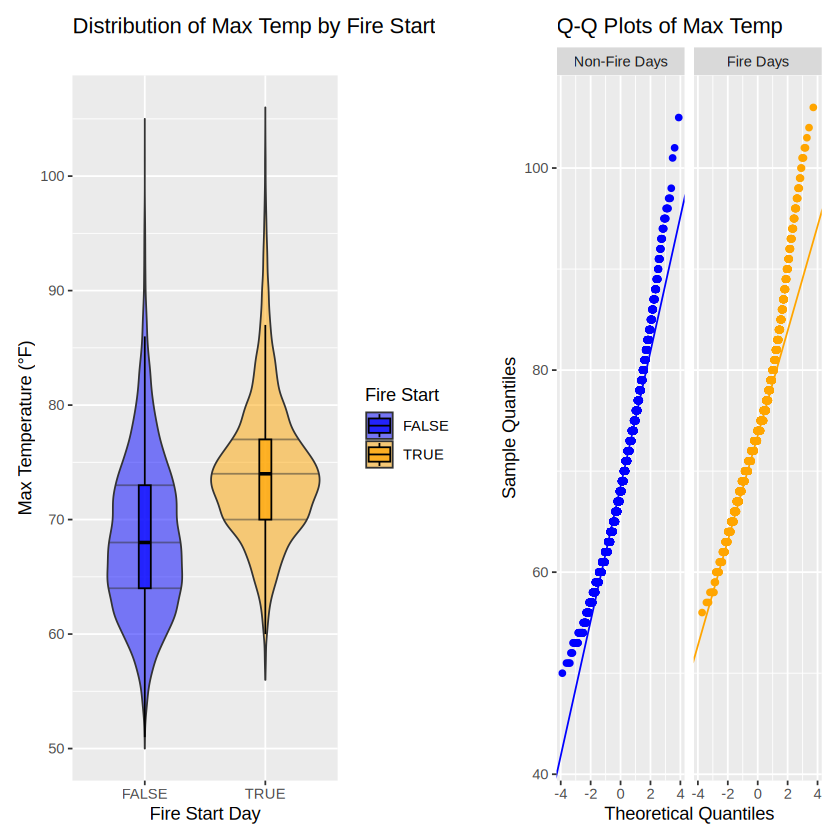

In [39]:
library(ggplot2)
library(patchwork)

p_violin <- CA_fire |>
  filter(!is.na(MAX_TEMP) & !is.na(FIRE_START_DAY)) |>
  ggplot(aes(x = FIRE_START_DAY, y = MAX_TEMP, fill = FIRE_START_DAY)) +
  geom_violin(alpha = 0.5, draw_quantiles = c(0.25, 0.5, 0.75)) +
  geom_boxplot(width = 0.1, color = "black", alpha = 0.7, outlier.shape = NA) +
  scale_fill_manual(values = c("FALSE" = "blue", "TRUE" = "orange")) +
  labs(
    title = "Distribution of Max Temp by Fire Start",
    x = "Fire Start Day",
    y = "Max Temperature (°F)",
    fill = "Fire Start"
  )

p_qq <- CA_fire |>
  filter(!is.na(MAX_TEMP) & !is.na(FIRE_START_DAY)) |>
  ggplot(aes(sample = MAX_TEMP, color = FIRE_START_DAY)) +
  stat_qq() +
  stat_qq_line() +
  facet_wrap(~FIRE_START_DAY, labeller = as_labeller(c("FALSE" = "Non-Fire Days", "TRUE" = "Fire Days"))) +
  scale_color_manual(values = c("FALSE" = "blue", "TRUE" = "orange")) +
  labs(
    title = "Q-Q Plots of Max Temp",
    x = "Theoretical Quantiles",
    y = "Sample Quantiles"
  ) +
  theme(legend.position = "none")

p_violin + p_qq + plot_layout(ncol = 2)

In [50]:
library(dplyr)

weather_summary <- CA_fire |>
  filter(!is.na(FIRE_START_DAY)) |>
  group_by(FIRE_START_DAY) |>
  summarise(
    Count = n(),
    Mean_Max_Temp = mean(MAX_TEMP, na.rm = TRUE),
    SD_Max_Temp = sd(MAX_TEMP, na.rm = TRUE),
    Mean_Wind_Speed = mean(AVG_WIND_SPEED, na.rm = TRUE),
    SD_Wind_Speed = sd(AVG_WIND_SPEED, na.rm = TRUE)
  )

print(weather_summary)

# A tibble: 2 × 6
  FIRE_START_DAY Count Mean_Max_Temp SD_Max_Temp Mean_Wind_Speed SD_Wind_Speed
  <lgl>          <int>         <dbl>       <dbl>           <dbl>         <dbl>
1 FALSE          10017          68.7        6.99            7.39          2.34
2 TRUE            4971          74.3        6.25            7.53          1.62


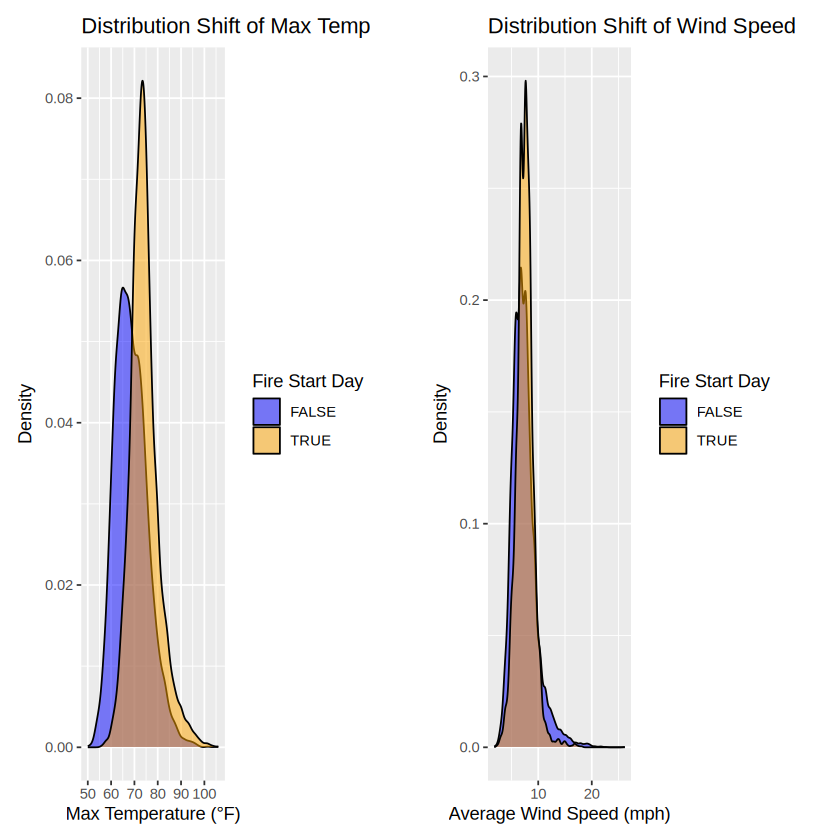

In [42]:
p1 <- CA_fire |>
  filter(!is.na(MAX_TEMP) & !is.na(FIRE_START_DAY)) |>
  ggplot(aes(x = MAX_TEMP, fill = FIRE_START_DAY)) +
  geom_density(alpha = 0.5) +
  scale_fill_manual(values = c("FALSE" = "blue", "TRUE" = "orange")) +
  labs(
    title = "Distribution Shift of Max Temp",
    x = "Max Temperature (°F)",
    y = "Density",
    fill = "Fire Start Day"
  )

p2 <- CA_fire |>
  filter(!is.na(AVG_WIND_SPEED) & !is.na(FIRE_START_DAY)) |>
  ggplot(aes(x = AVG_WIND_SPEED, fill = FIRE_START_DAY)) +
  geom_density(alpha = 0.5) +
  scale_fill_manual(values = c("FALSE" = "blue", "TRUE" = "orange")) +
  labs(
    title = "Distribution Shift of Wind Speed",
    x = "Average Wind Speed (mph)",
    y = "Density",
    fill = "Fire Start Day"
  )

p1 + p2 + plot_layout(ncol = 2)